## **0. Dependencies, Constants, and Function References**

**Note:** Run this section once before anything else. It holds everything the rest of the notebook relies on:

- The imports
- Constants (class names, box colors, file paths, tracker config)
- and the function references used for tracking, counting, drawing, and logging.

These do not change from one clip to the next, so they are defined here once and not repeated in every section.   
After that, we can go straight to whichever clip we’re interested in. Each clip has its own section and doesn’t depend on the others, so there’s no need to run them in order.   
Within a clip’s section, run the cells from top to bottom, since each step there builds on the one before it.

### **0.1 Imports**

In [1]:
# Standard lib
import pickle
import time
import yaml

# 3rd-party libraries
import cv2
from matplotlib import pyplot as plt 
import matplotlib.patches as patches
from matplotlib.patches import Polygon 
import numpy as np
import pandas as pd
from PIL import Image

!python -m pip install -q ultralytics 
import ultralytics 
from ultralytics import YOLO

%matplotlib widget


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### **0.2 Constants**

In [2]:
CLASS_MAP = {2:"car", 3:"motorcycle", 5:"bus", 7:"truck"}

BOX_COLORS = {
    2: (255, 255, 255),  # car (white)
    3: (255, 200, 100),  # motorcycle (light blue)
    5: (203, 192, 255),  # bus (pink)
    7: (0, 255, 255)}   # truck (yellow)

OUTPUTS_DIR = "../outputs"
STUDY_CLIPS_DIR = "../data/Eval_Clips/Eval_Study_Clips"
CONFIG_DIR = "../config"
TRACK_BF60 = f"{CONFIG_DIR}/bytetrack_w_buffer60.yaml"


### **0.3 References**

#### **0.3.1 Visualize Line and Detection Zone**

In [3]:
def get_frame(vid_file, frame_idx, fmt="RGB"):
    """For capturing a single frame specified by index"""
    cap = cv2.VideoCapture(vid_file)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = cap.read()
    cap.release()
    
    if not ret: return
    if fmt == "RGB":
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame


def setup_frame_axes(ax, frame):
    """Configure axes for displaying a video frame."""
    h, w = frame.shape[:2]
    ax.imshow(frame)
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.axis("off")
    

def show_frame(frame):
    """Display the frame to manually pick line and zone coords."""
    fig, ax = plt.subplots(1, figsize=(16, 9))
    setup_frame_axes(ax, frame)
    plt.tight_layout()
    plt.show()


def draw_lines_and_zone(frame, lines=None, zone_polys=None):
    """For drawing counting lines and roi polygons to a frame"""
    fig, ax = plt.subplots(1, figsize=(16, 9))
    setup_frame_axes(ax, frame)

    if zone_polys:
        for zone in zone_polys:
            zone_poly = Polygon(zone, closed=True, 
                                facecolor='green', alpha=0.2,
                                edgecolor='lime', 
                                linewidth=2)
            ax.add_patch(zone_poly)
            
    if lines:
        for line in lines:
            line_poly = Polygon(line, closed=True, 
                                facecolor='red', edgecolor='red', 
                                linewidth=2)
            ax.add_patch(line_poly)

    plt.tight_layout()
    plt.show()


def scale_line(line, k, anchor="mid"):
    """
    Lengthen (k > 1) or shorten (k < 1) a line without changing its angle.
    anchor="mid" keeps the midpoint fixed and stretches both ends,
    anchor="start" keeps the first (left) point fixed and moves the right end,
    anchor="end" keeps the second (right) point fixed and moves the left end.
    """
    (x1, y1), (x2, y2) = line
    if anchor == "mid":
        fx, fy = (x1 + x2) / 2, (y1 + y2) / 2
    elif anchor == "start":
        fx, fy = x1, y1
    elif anchor == "end":
        fx, fy = x2, y2
    else:
        raise ValueError("anchor must be 'mid', 'start', or 'end'")

            # Dilation formula
    return [[round(fx + k * (x1 - fx)), round(fy + k * (y1 - fy))],
            [round(fx + k * (x2 - fx)), round(fy + k * (y2 - fy))]]

#### **0.3.2 Detection and Tracking**

In [4]:
def generate_detections(cap, model, out_fname, track_file):
    """
    Generate an annotated video output with detections
    and tracking. The main goal is to observe detection 
    behavior (confidence scores, box accuracy) using a study clip 
    (clip from the same source as an eval clip) to best determine 
    where to position the counting line and zone on that road
    """
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"(W,H): ({w},{h})")
    print(f"video fps: {fps}")
    print(f"Total frames: {total_frames}")

    start = time.time()
    frame_ctr = 0
    all_dets = []
    
    out = cv2.VideoWriter(out_fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        tracked_detections, results = track_vehicles(frame, 
                                                     model, 
                                                     agnos_nms=True, 
                                                     track_file=track_file)

        annot_res = results[0].plot(font_size=17, pil=True)
        out.write(cv2.cvtColor(np.array(annot_res), cv2.COLOR_RGB2BGR))
        all_dets.append(tracked_detections)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()
    
    print(f"Duration: {elapsed:.1f}s")
    print(f"processing fps: {frame_ctr/elapsed:.1f}")
    return all_dets


def track_vehicles(frame, model, agnos_nms=True, track_file="bytetrack.yaml"):
    """
    Detect and track vehicles in a single frame and return a list of dicts 
    (one dict per tracked vehicle). Call it on consecutive frames with the same 
    model and tracker config so that track IDs carry over from frame to frame.
    """

    # Detect COCO classes that are vehicles only 
    # Also, keep tracker state between calls
    results = model.track(frame, 
                          classes=[2,3,5,7],
                          conf=0.25,
                          agnostic_nms=agnos_nms,
                          verbose=False,
                          persist=True, 
                          tracker=track_file)

    track_ids = results[0].boxes.id

    if track_ids is None:
        return [], results

    boxes = results[0].boxes.xyxy
    conf_scores = results[0].boxes.conf
    cls_ids = results[0].boxes.cls

    # Convert the tensors into one plain dict per tracked vehicle
    tracked_detections = []
    for box, score, cls_id, tr_id in zip(boxes, conf_scores, cls_ids, track_ids):

        prediction = {"box": box.tolist(),
                      "conf_score": score.item(),
                      "cls_id": cls_id.item(),
                      "track_id": tr_id.item()}

        tracked_detections.append(prediction)
    
    return tracked_detections, results

#### **0.3.3 Counting**

In [5]:
def in_roi(roi, anchor_point):
    """Return True if anchor_point lies 
    inside or on the edge of the polygon roi."""
    polygon = np.array(roi, dtype=np.int32)
    return cv2.pointPolygonTest(polygon, anchor_point, False) >= 0
    

class LineCrossingCounter:
    """
    Counts vehicles crossing a single counting line. The counter 
    keeps track of which side of the line each track is on and records
    a crossing when a track moves to the other side and stays there for
    hys_n consecutive sightings. Only vehicles inside the line's ROI are
    considered. Create one counter per line.
    """
    def __init__(self, source, fps, line_id, 
                 line, roi, dir_labels, cooldown=30,
                 hys_n=1):
        
        self.source = source
        self.fps = fps
        self.line_id = line_id
        self.line = line
        self.roi = roi
        self.dir_labels = dir_labels
        self.cooldown = cooldown
        self.last_crossed = {}
        self.tentative_crossed = {}
        self.track_sides = {}
        self.hys_n = hys_n

        self.counts = {self.dir_labels["positive"]:0, 
                       self.dir_labels["negative"]:0}

        self.events = []

    def update(self, tracked_detections, frame_number):

        for detection in tracked_detections:

            box = detection["box"]
            x_anchor = (box[0] + box[2]) /2
            y_anchor = box[3]

            # Check first if the anchor point lies within the roi or along its edges
            # If it does, proceed with the rest of the sequence, else skip the 
            # anchor point entirely from being recorded and counted relative to this line
            if not in_roi(self.roi, (x_anchor, y_anchor)):
                continue

            x1, x2 = self.line[0][0], self.line[1][0]
            y1, y2 = self.line[0][1], self.line[1][1]
            cross_product = (x2 - x1) * (y_anchor - y1) - (y2 - y1) * (x_anchor - x1)

            # The sign of the cross-product tells which 
            # side of the line the anchor is on
            sign = "positive" if cross_product > 0 else "negative"
            track_id = detection["track_id"]

            # The track is new so its current side 
            # immediately becomes its confirmed side
            if track_id not in self.track_sides:
                self.track_sides[track_id] = sign
                continue

            # The track is still on its confirmed side 
            # so a pending flip is cancelled
            if sign == self.track_sides[track_id]:
                self.tentative_crossed.pop(track_id, None)
                continue

            # The track is on the other side 
            # Start or continue a pending flip
            if track_id not in self.tentative_crossed:
                self.tentative_crossed[track_id] = {"flip_frame": frame_number, 
                                                    "flip_cls": detection["cls_id"],
                                                    "count": 0}

            # Add 1 to count for one more sighting on the other side
            self.tentative_crossed[track_id]["count"] += 1

            # If number of frames remained on the new side is 
            # less than hys_n, wait for the next frame
            if self.tentative_crossed[track_id]["count"] < self.hys_n:
                continue 

            # The flip held for hys_n frames so it is committed
            pending = self.tentative_crossed.pop(track_id)
            flip_frame = pending["flip_frame"]
            self.track_sides[track_id] = sign

            # Skip the count if this track already crossed 
            # within the last `cooldown` frames
            if track_id in self.last_crossed:
                if flip_frame - self.last_crossed[track_id] <= self.cooldown:
                    continue

            # Count the crossing and date it at the 
            # crossing frame where the flip started
            self.last_crossed[track_id] = flip_frame
            self.counts[self.dir_labels[sign]] += 1

            # Build the event log and append to the event list
            event = {
                "source_video": self.source,
                "line_id": self.line_id,
                "vehicle_id": track_id, 
                "frame_number": flip_frame,
                "timestamp": flip_frame / self.fps,
                "direction": self.dir_labels[sign],
                "class": CLASS_MAP[pending["flip_cls"]]}

            self.events.append(event)

#### **0.3.4 Results Logging**

In [6]:
class FrameLogger:
    """
    Accumulates per-frame records into a DataFrame for later
    analysis. One row per detection per frame.
    """
    def __init__(self, counters):
        self.container = []
        self.counters = counters
        self.sign_cols = [c.line_id for c in counters]   
        
    # Append one row corresponding to a single detection in the current frame
    def log(self, frame_n, tracked_detection):
        track_id = tracked_detection["track_id"]
        box = tracked_detection["box"]        
        area = (box[2] - box[0]) * (box[3] - box[1])
        anchor = (box[0] + box[2]) /2, box[3]
                             
        signs = []
        for counter in self.counters:
            sign = counter.track_sides.get(track_id)
            signs.append(sign if sign else "N/A")
        
        self.container.append([frame_n,
                               track_id,
                               box,
                               area,
                               anchor,
                               *signs])
        
    # Return all logged rows as a DataFrame
    def to_dataframe(self):
        columns = ["frame_n",
                   "track_id",
                   "box (xyxy)",
                   "box area",
                   "anchor (xy)",
                   *self.sign_cols]
        
        return pd.DataFrame(self.container, columns=columns)


    def get_span(self, line_id, side="positive"):
        """
        For each crossing onto `side` of `line_id`, measure how long the track
        stayed there. Only runs that start right after the track was seen on
        the opposite side are counted. Use the log from a hys_n=1 run.
        """
        other = "negative" if side == "positive" else "positive"

        log_df = self.to_dataframe()
        print(f"No. of records: {log_df.shape[0]}")

        # Drop rows where the track is outside this line's counting zone ("N/A"),
        # then sort so each track's rows are ordered by frame number        
        df = log_df.loc[log_df[line_id] != "N/A", ["track_id", "frame_n", line_id]]
        df = df.sort_values(["track_id", "frame_n"])

        # Within a track, number each run of same-side sightings
        prev = df.groupby("track_id")[line_id].shift()
        run = (df[line_id] != prev).groupby(df["track_id"]).cumsum()
        df = df.assign(prev=prev, run=run)

        # Keep only runs on `side` that came directly from the opposite side
        starts = df.loc[(df[line_id] == side) & (df["prev"] == other), ["track_id", "run"]]
        runs = df.merge(starts, on=["track_id", "run"])

        summary = runs.groupby(["track_id", "run"]).agg(
            count=("frame_n", "size"),
            first_frm=("frame_n", "min"),
            last_frm=("frame_n", "max"),
        ).reset_index()

        summary["span"] = summary["last_frm"] - summary["first_frm"] + 1
        summary["contiguous"] = summary["count"] == summary["span"]
        return summary.drop(columns="run").sort_values("count")


def get_scores(line_ids, true_totals, sys_totals, phant_counts, misses):
    """Per-line and whole-clip accuracy metrics, as defined in SPEC.md."""
    
    df = pd.DataFrame({"true_total": true_totals,
                       "sys_total": sys_totals,
                       "phantoms": phant_counts,
                       "misses": misses},
                      index=line_ids)
    df.loc["total"] = df.sum()

    # The tally only adds up if every extra and every miss was found
    off = (df["sys_total"] - df["true_total"]) != (df["phantoms"] - df["misses"])
    if off.any():
        print(f"Check the tally for: {list(df.index[off])}")

    df["net_count_err"] = ((df["sys_total"] - df["true_total"]).abs() / df["true_total"]).round(3)
    df["gross_error_rate"] = ((df["misses"] + df["phantoms"]) / df["true_total"]).round(3)
    return df

#### **0.3.5 Orchestration**

`process_clip` runs counting on a clip and writes the annotated video. It works in two modes:

1. **Model inference.** When no saved detections are passed, it runs `model.track()` on every frame. Provide a `save_path` so it also saves the detections to a pickle file.
2. **Replay.** when `saved_dets` is passed, it uses those detections and skip `model.track()`, so `model` can be None.

The `counters` objects are updated in place. The function returns the frame logger (or None if `log_frames` is off) and the list of detections used in the run.

In [7]:
def process_clip(cap, out_fname, model, counters,  
                 saved_dets=None, 
                 save_path=None,
                 track_file="bytetrack.yaml",
                 log_frames=False):
    """Run counting on a clip and write an annotated video. """
    
    replay = saved_dets is not None
    
    if model is None and not replay:
        raise ValueError("Pass a model to run inference, or saved_dets to replay.")

    # Capture and display essential clip information
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) 
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  
    print(f"Mode: {'replay of saved detections' if replay else 'model inference'}")
    print(f"(W,H): ({w},{h})")
    print(f"Video FPS: {fps}")
    print(f"Total frames: {total_frames}")   

    if replay and len(saved_dets) != total_frames:
        print(f"Warning: {len(saved_dets)} saved frames vs {total_frames} frames in the clip")

    start = time.time() 
    frame_ctr = 0

    # For counting the total unique IDs that appeared across all frames
    unique_ids = set()   

    # Detections used in this run, one list of dicts per frame
    all_dets = []
    
    out = cv2.VideoWriter(out_fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    logger = FrameLogger(counters) if log_frames else None

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Retrieve previously stored detections or generate new ones
        if replay:
            if frame_ctr >= len(saved_dets): break
            tracked_detections = saved_dets[frame_ctr]
        else:
            tracked_detections, _ = track_vehicles(frame, 
                                                   model, 
                                                   agnos_nms=True, 
                                                   track_file=track_file)

        all_dets.append(tracked_detections)

        # Capture unique IDs
        unique_ids.update([d["track_id"] for d in tracked_detections])

        # Update counter states for all LineCrossingCounter objects
        for counter in counters:
            counter.update(tracked_detections, frame_ctr)

        # Log the current frame's information 
        if log_frames:
            for detection in tracked_detections:
                logger.log(frame_ctr, detection)

        # Draw lines, boxes, labels, and counts, then write the frame
        draw_annotations(frame, tracked_detections, counters)
        out.write(frame)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    # Save the detections from an inference run for later replays
    if save_path is not None and not replay:
        with open(save_path, "wb") as f:
            pickle.dump(all_dets, f)
        print(f"Saved detections for {len(all_dets)} frames to {save_path}")

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"Processing FPS: {frame_ctr/elapsed:.1f}")

    return logger, all_dets

In [8]:
def draw_annotations(frame, tracked_detections, counters):
    """
    Draw the counting lines, the detection boxes with their labels, and
    the count overlay on a frame. The frame is modified in place.
    Originally integrated within the process_clips function.
    """

    # Draw the counting lines
    for counter in counters:
        cv2.line(frame, counter.line[0], counter.line[1], (0, 0, 255), 3)

    # Draw the detected boxes with ID, class, and current signs
    for detection in tracked_detections:
        x1, y1, x2, y2 = [int(v) for v in detection["box"]]

        # Draw a thin gray box with no label for every box
        # anchor point that falls outside every counting zone 
        anchor = ((x1 + x2) / 2, y2)
        if not any(in_roi(c.roi, anchor) for c in counters):
            cv2.rectangle(frame, (x1, y1), (x2, y2), (160, 160, 160), 1)
            continue
        
        track_id = detection["track_id"]
        cls_id = int(detection["cls_id"])
        color = BOX_COLORS[cls_id]
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 6)

        signs_lst = [f"{counter.line_id[0:3]}:"
                     f"{ {'positive': '+', 'negative': '-'}.get(counter.track_sides.get(track_id), 'N/A') }"
                     for counter in counters]
        signs_str = ", ".join(signs_lst)

        label = (f"ID:{int(track_id)}, "
                 f"{CLASS_MAP[cls_id]}, "
                 f"{detection['conf_score']:.2f}, "
                 f"{signs_str}")

        (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        top = max(y1 - baseline - th - 8, 0)

        cv2.rectangle(frame, (x1, top), (x1 + tw + 8, top + th + baseline + 8), color, -1)
        cv2.putText(frame, label,
                    (x1 + 4, top + th + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    # Draw the counting overlay to show counts for each line crossing
    texts = []
    for counter in counters:
        total_count = sum(counter.counts.values())
        pos = counter.counts[counter.dir_labels['positive']]
        neg = counter.counts[counter.dir_labels['negative']]
        texts.append(f"{counter.line_id.upper()} TOTAL: {total_count}, "
                     f"POSITIVE: {pos}, NEGATIVE: {neg}")

    # Set background dimension based on the widest line and the number of lines
    font, scale, thick = cv2.FONT_HERSHEY_DUPLEX, 0.9, 2
    max_w = max(cv2.getTextSize(t, font, scale, thick)[0][0] for t in texts)
    cv2.rectangle(frame, (30, 80), (50 + max_w, 135 + (len(texts) - 1) * 50), (0, 0, 0), -1) 

    for row, text in enumerate(texts):
        cv2.putText(frame, text, (40, 120 + row * 50), font, scale,
                    (255, 255, 255), thick, cv2.LINE_AA)

## **1. Determining Settings for Each Eval Clip Using a Study Clip**

The results on the eval clips will be reliable as a measure of performance only if the system was not tuned on them in any way. For this reason, we need to treat each eval clip as an entirely new clip. We cannot check their errors in advance or use detection, tracking and counting results to determine where to best position the counting lines. So for evaluation, we are not going to conduct the same trial and error process that we did on the dev clips (configuring settings until their counts improved).

A real operator setting up a similar system would first watch past footage from the camera setup to become familiar with the road and learn where occlusions can occur and where vehicles tend to congest. We do the same with a **study clip**, a few minutes from the same recording as the eval clip, taken from before or after it, with no overlap and the camera unchanged.

On each study clip we:

- watch the detections (with `generate_detections`) to see where boxes are steady and confident,
- place the counting lines and zones,
- run counting, measure M for each line, and set `hys_n`.

These settings go into `eval_config.yaml`, which is committed before any eval clip is run. Each eval clip is then run once, and that result is the one we are going to report.

## **2. `eval_overhead_heavy_01.mp4` - Determine Eval Settings Using a Study Clip**

- **Study clip used:** `study_eval_overhead_heavy_01.mp4`
- **Study clip duration:** 4 minutes

### **2.1 Generate and Observe Detections on the Study Clip**

In [9]:
cap1 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_overhead_heavy_01.mp4")
model = YOLO("yolov8m.pt")
out_fname = f"{OUTPUTS_DIR}/track_study_eval_overhead_heavy_01.mp4"
all_dets1 = generate_detections(cap1, model, out_fname, TRACK_BF60)

# Save the detections for later replays
with open(f"{OUTPUTS_DIR}/study_eval_overhead_heavy_01.pkl", "wb") as f:
    pickle.dump(all_dets1, f)
print(f"Saved detections for {len(all_dets1)} frames") 

(W,H): (1920,1080)
video fps: 25.0
Total frames: 6000
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 352ms
Prepared 1 package in 47ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

200/6000 processed
400/6000 processed
600/6000 processed
800/6000 processed
1000/6000 processed
1200/6000 processed
1400/6000 processed
1600/6000 processed
1800/6000 processed
2000/6000 processed
2200/6000 processed
2400/6000 processed
2600/6000 processed
2800/6000 processed
3000/6000 processed
3200/6000 processed
3400/6000 processed
3600/6000 processed
3800/6000 processed
4000/6000 processed
4200/6000 processed
4400/6000 processed
4600/6000 processed
4800/6000 processed
5000/6000 processed
5200/6000 processed
5400/6000 processed
5600/6000 processed
5800/6000 processed
6000/6000 pro

### **2.2 Determine Counting Line and Zone Coordinates**

Frame shape (1080, 1920, 3)


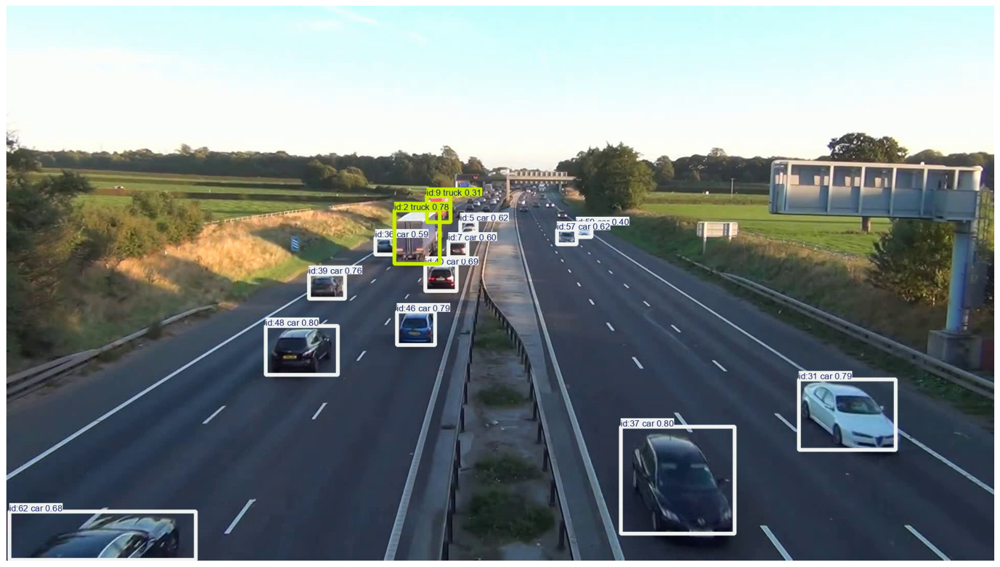

In [12]:
fpath = f"{OUTPUTS_DIR}/track_study_eval_overhead_heavy_01.mp4"
frame = get_frame(fpath, 111)
print(f"Frame shape {frame.shape}")
show_frame(frame)

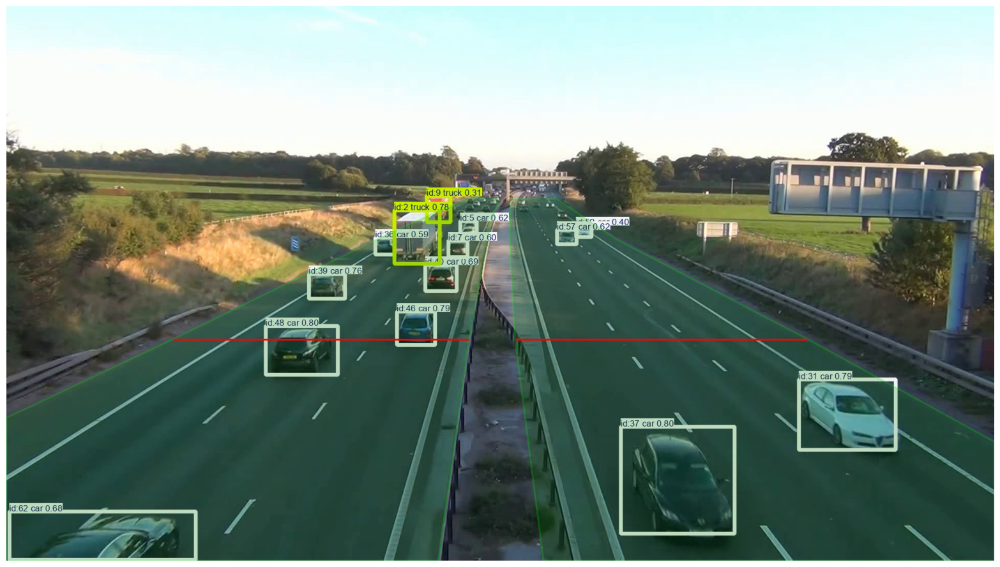

In [13]:
# Coordinates are taken from the matplotlib plot readout
# which appears when hovering the mouse over a plot
sclip1_out_line = [[324, 649], [899, 649]]
sclip1_inc_line = [[989, 649], [1558, 649]]
sclip1_lines = [sclip1_out_line, sclip1_inc_line]

sclip1_out_zone = [[0,1080], [0,802], [324,649], [747,442], [846,397], [902,376],
                   [958,376], [941,427], [899,649], [840, 1080]]
sclip1_inc_zone = [[1044,1080], [989,649], [978,447], [982,376], 
                   [1070,376], [1185,454], [1558,649], [1558,649], [1920,848], [1920,1080]]
sclip1_zones = [sclip1_out_zone, sclip1_inc_zone]

draw_lines_and_zone(frame, sclip1_lines, sclip1_zones)

### **2.3 Study Clip First Counting Run**

In [ ]:
dir_labels = {"negative": "A --> B", "positive": "B --> A"}
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_overhead_heavy_01.mp4")
cap1fps = round(cap1.get(cv2.CAP_PROP_FPS))

# Create the counters
sclip1source = "study_eval_overhead_heavy_01.mp4"
sclip1_ctr1 = LineCrossingCounter(sclip1source, cap1fps, "incoming", 
                                  sclip1_inc_line, sclip1_inc_zone, 
                                  dir_labels, hys_n=1) 
sclip1_ctr2 = LineCrossingCounter(sclip1source, cap1fps, "outgoing", 
                                  sclip1_out_line, sclip1_out_zone, 
                                  dir_labels, hys_n=1)
sclip1_ctrs1 = (sclip1_ctr1, sclip1_ctr2)

with open(f"{OUTPUTS_DIR}/study_eval_overhead_heavy_01.pkl", "rb") as f:
    sclip1_saved = pickle.load(f)

sclip1_log1, sclip1_dets = process_clip(cap=cap1, 
                           out_fname=f"{OUTPUTS_DIR}/study_eval_overhead_heavy_01_hysn1.mp4", 
                           model=None,
                           counters=sclip1_ctrs1, 
                           save_path=None, 
                           saved_dets=sclip1_saved, 
                           track_file=TRACK_BF60,
                           log_frames=True)

In [13]:
line_ids = ["incoming", "outgoing"]
true_totals = [290, 335]
sys_totals = [290, 331]
phantoms = [0, 2]
misses = [0, 6]

get_scores(line_ids, true_totals, sys_totals, phantoms, misses)

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,290,290,0,0,0.000,0.000
outgoing,335,331,2,6,0.012,0.024
total,625,621,2,6,0.006,0.013


**Observations and Next Step:** Overall, great scores. 5 of 6 misses in the outgoing direction are caused by trucks occluding cars in the leftmost lane. The other miss is another undetected motorcycle (ongoing issue). All the occluded cars reappear just past the current line so we can try moving the outgoing line a bit further away from the camera to capture them. All two outgoing phantom counts are split detections, which also disappear just past the current line so moving the line can also eliminate them.

### **2.4 Second Counting Run (Outgoing Line Moved Further from the Camera)**

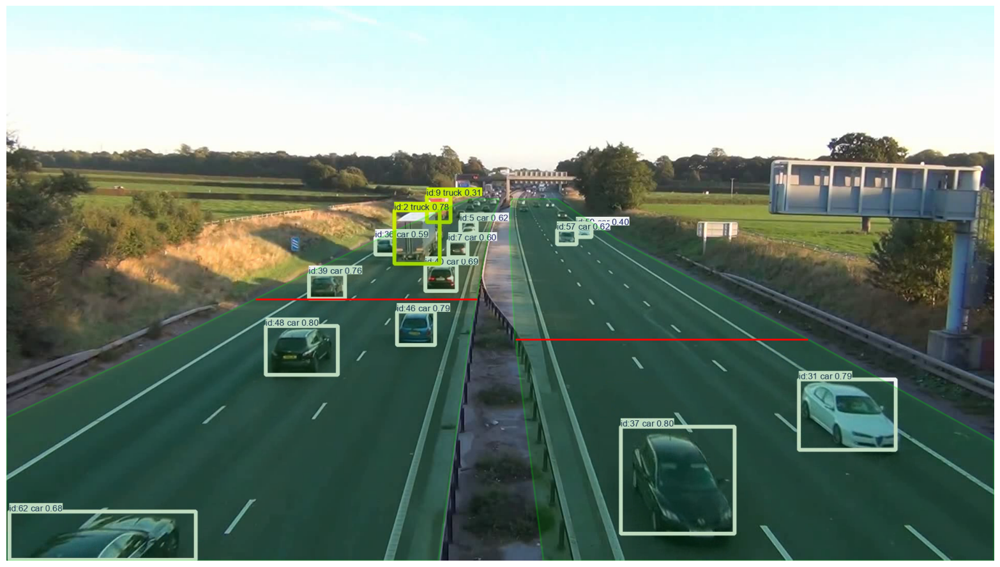

In [35]:
fpath = f"{OUTPUTS_DIR}/track_study_eval_overhead_heavy_01.mp4"
frame = get_frame(fpath, 111)

sclip1_out_line = [[484, 571], [915, 571]]
sclip1_inc_line = [[989, 649], [1558, 649]]
sclip1_lines = [sclip1_out_line, sclip1_inc_line]

sclip1_out_zone = [[0,1080], [0,802], [324,649], [747,442], [846,397], [902,376],
                   [958,376], [941,427], [899,649], [840, 1080]]
sclip1_inc_zone = [[1044,1080], [989,649], [978,447], [982,376], 
                   [1070,376], [1185,454], [1558,649], [1920,848], [1920,1080]]
sclip1_zones = [sclip1_out_zone, sclip1_inc_zone]

draw_lines_and_zone(frame, sclip1_lines, sclip1_zones)

In [36]:
dir_labels = {"negative": "A --> B", "positive": "B --> A"}
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_overhead_heavy_01.mp4")
cap1fps = round(cap1.get(cv2.CAP_PROP_FPS))

# Create the counters
sclip1source = "study_eval_overhead_heavy_01.mp4"
sclip1_ctr1_2 = LineCrossingCounter(sclip1source, cap1fps, "incoming", 
                                  sclip1_inc_line, sclip1_inc_zone, 
                                  dir_labels, hys_n=1) 
sclip1_ctr2_2 = LineCrossingCounter(sclip1source, cap1fps, "outgoing", 
                                  sclip1_out_line, sclip1_out_zone, 
                                  dir_labels, hys_n=1)
sclip1_ctrs2 = (sclip1_ctr1_2, sclip1_ctr2_2)

with open(f"{OUTPUTS_DIR}/study_eval_overhead_heavy_01.pkl", "rb") as f:
    sclip1_saved = pickle.load(f)

sclip1_log2, sclip1_dets = process_clip(cap=cap1, 
                           out_fname=f"{OUTPUTS_DIR}/study_eval_overhead_heavy_01_h1_updline.mp4", 
                           model=None,
                           counters=sclip1_ctrs2, 
                           save_path=None, 
                           saved_dets=sclip1_saved, 
                           track_file=TRACK_BF60,
                           log_frames=True)

Mode: replay of saved detections
(W,H): (1920,1080)
Video FPS: 25.0
Total frames: 6000
200/6000 processed
400/6000 processed
600/6000 processed
800/6000 processed
1000/6000 processed
1200/6000 processed
1400/6000 processed
1600/6000 processed
1800/6000 processed
2000/6000 processed
2200/6000 processed
2400/6000 processed
2600/6000 processed
2800/6000 processed
3000/6000 processed
3200/6000 processed
3400/6000 processed
3600/6000 processed
3800/6000 processed
4000/6000 processed
4200/6000 processed
4400/6000 processed
4600/6000 processed
4800/6000 processed
5000/6000 processed
5200/6000 processed
5400/6000 processed
5600/6000 processed
5800/6000 processed
6000/6000 processed
Total unique IDs: 829
Duration: 126.6s
Processing FPS: 47.4


In [16]:
line_ids = ["incoming", "outgoing"]
true_totals = [290, 338]
sys_totals = [290, 337]
phantoms = [0, 0]
misses = [0, 1]

get_scores(line_ids, true_totals, sys_totals, phantoms, misses)

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,290,290,0,0,0.000,0.000
outgoing,338,337,0,1,0.003,0.003
total,628,627,0,1,0.002,0.002


**Observation:** Moving the outgoing line further away from the camera improved its score with 0 phantoms and 1 miss (GER 0.3%, down from 2.4%). The 5 cars hidden behind trucks at the previous line position are now counted, and the 2 split detections no longer cross the line. The only miss left is the undetected motorcycle. The outgoing true total went from 335 to 338 because moving the line also changes which vehicles cross it during the whole clip's duration.

**See the output video [here](https://youtu.be/ketHikmUMQA).**

**Final Config: `study_eval_overhead_heavy_01`**

| Line | Counting line (left to right) | Counting zone | `hys_n` |
|---|---|---|---|
| Incoming | `[[989, 649], [1558, 649]]` | `[[1044, 1080], [989, 649], [978, 447], [982, 376], [1070, 376], [1185, 454], [1558, 649], [1920, 848], [1920, 1080]]` | 1 |
| Outgoing | `[[484, 571], [915, 571]]` | `[[0, 1080], [0, 802], [324, 649], [747, 442], [846, 397], [902, 376], [958, 376], [941, 427], [899, 649], [840, 1080]]` | 1 |

`track_buffer=60` and `cooldown=30` on both lines. These settings carry over to `eval_overhead_heavy_01`.

## **3. `eval_overhead_medium_01.mp4` - Determine Eval Settings Using a Study Clip**

- **Study clip used:** `study_eval_overhead_medium_01.mp4`
- **Study clip duration:** 4 minutes

### **3.1 Generate and Observe Detections on the Study Clip**

In [17]:
cap2 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_overhead_medium_01.mp4")
model = YOLO("yolov8m.pt")
out_fname = f"{OUTPUTS_DIR}/track_study_eval_overhead_medium_01.mp4"
all_dets2 = generate_detections(cap2, model, out_fname, TRACK_BF60)

# Save the detections for later replays
with open(f"{OUTPUTS_DIR}/study_eval_overhead_medium_01.pkl", "wb") as f:
    pickle.dump(all_dets2, f)
print(f"Saved detections for {len(all_dets2)} frames")  

(W,H): (1280,720)
video fps: 29.97002997002997
Total frames: 7193
200/7193 processed
400/7193 processed
600/7193 processed
800/7193 processed
1000/7193 processed
1200/7193 processed
1400/7193 processed
1600/7193 processed
1800/7193 processed
2000/7193 processed
2200/7193 processed
2400/7193 processed
2600/7193 processed
2800/7193 processed
3000/7193 processed
3200/7193 processed
3400/7193 processed
3600/7193 processed
3800/7193 processed
4000/7193 processed
4200/7193 processed
4400/7193 processed
4600/7193 processed
4800/7193 processed
5000/7193 processed
5200/7193 processed
5400/7193 processed
5600/7193 processed
5800/7193 processed
6000/7193 processed
6200/7193 processed
6400/7193 processed
6600/7193 processed
6800/7193 processed
7000/7193 processed
Duration: 294.2s
processing fps: 24.4
Saved detections for 7193 frames


### **3.2 Determine Counting Line and Zone Coordinates**

Frame shape (720, 1280, 3)


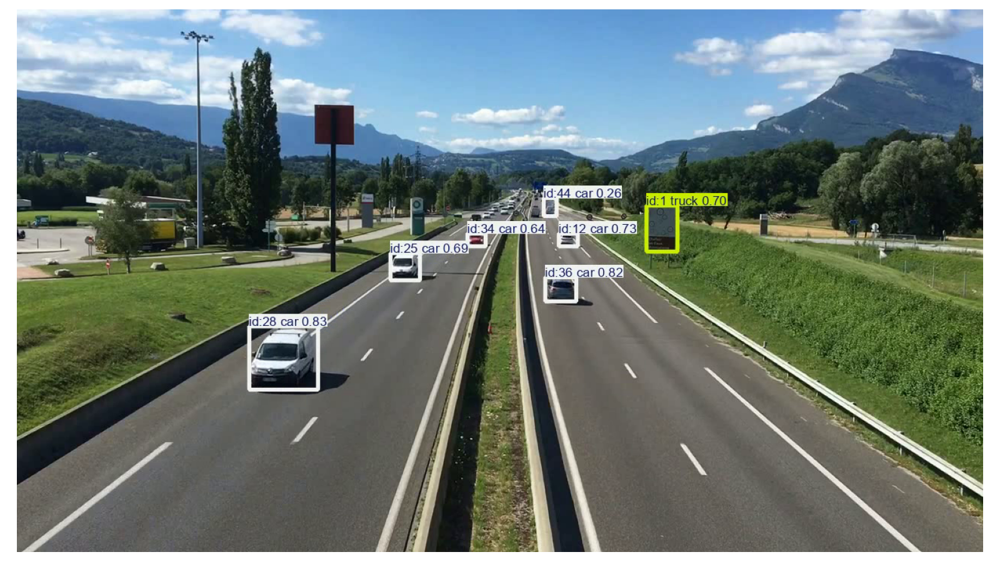

In [10]:
fpath = f"{OUTPUTS_DIR}/track_study_eval_overhead_medium_01.mp4"
frame = get_frame(fpath, 111)
print(f"Frame shape {frame.shape}")
show_frame(frame)

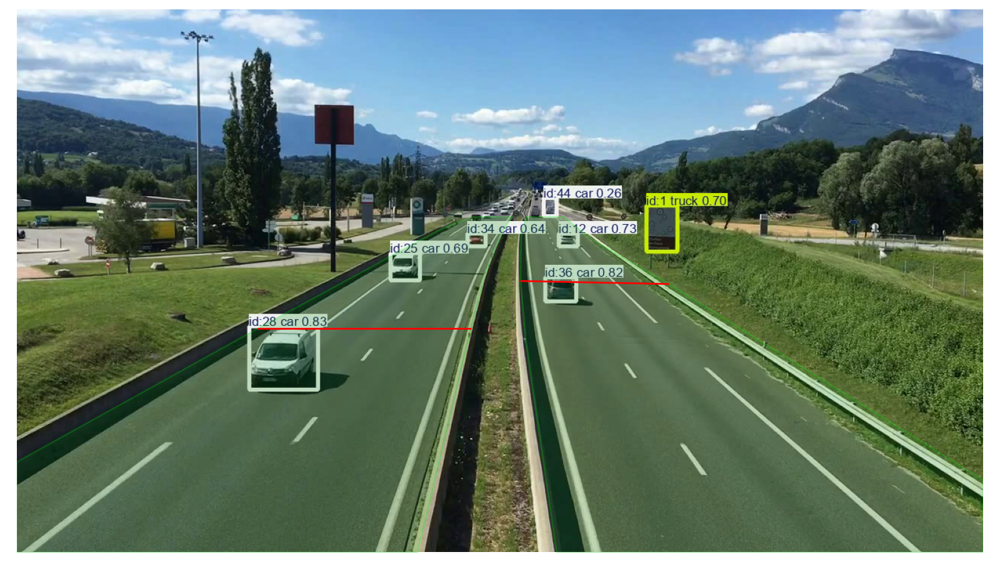

In [11]:
sclip2_inc_line = [[319, 423], [602, 423]]
sclip2_out_line = [[667, 360], [864, 364]]
sclip2_lines = [sclip2_inc_line, sclip2_out_line]

sclip2_inc_zone = [[0, 720], [0, 600], [319, 423], [562, 291], [604, 275],
                   [656, 275], [643, 295], [619, 355], [602, 423], [531, 720]]
sclip2_out_zone = [[715, 720], [674, 438], [667, 360], [668, 296], [675, 275],
                   [724, 275], [767, 308], [864, 364], [1280, 624], [1280, 720]]
sclip2_zones = [sclip2_inc_zone, sclip2_out_zone]

draw_lines_and_zone(frame, sclip2_lines, sclip2_zones)

**Observations:** 

1. A *merge lane* is present on the right but, as seen above, it joins the main road further down (possibly past the counting line). Vehicles on it are likely not going to be on the main road yet when they pass the outgoing line so they will not be part of the traffic that line will measure. We keep the merge lane out of the counting zone (and it will not be included in the hand count), so both totals cover only the main outgoing road lanes. The eval clip from this camera is set up and hand-counted the same way.

2. A traffic sign beside the road is detected as a truck for the whole clip (ID 1). While it is indeed a real object, it is not a vehicle so it is a false positive. Its anchor point is outside the outgoing counting zone so it will not be counted. In addition, it is stationary throughout the duration of the clip so it could not cross the line anyway.

**Note:** From here on, **every detection outside the counting zones will be drawn as a thin grey box with no label**. We will modify `draw_annotations` to make this happen so succeeding annotated output videos will reflect this change.

### **3.3 First Counting Run**

In [38]:
dir_labels = {"negative": "A --> B", "positive": "B --> A"}
model = YOLO("yolov8m.pt")
cap2 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_overhead_medium_01.mp4")
cap2fps = round(cap2.get(cv2.CAP_PROP_FPS))

# Create the counters
sclip2source = "study_eval_overhead_medium_01.mp4"
sclip2_ctr1 = LineCrossingCounter(sclip2source, cap2fps, "incoming", 
                                  sclip2_inc_line, sclip2_inc_zone, 
                                  dir_labels, hys_n=1) 
sclip2_ctr2 = LineCrossingCounter(sclip2source, cap2fps, "outgoing", 
                                  sclip2_out_line, sclip2_out_zone, 
                                  dir_labels, hys_n=1)
sclip2_ctrs1 = (sclip2_ctr1, sclip2_ctr2)

with open(f"{OUTPUTS_DIR}/study_eval_overhead_medium_01.pkl", "rb") as f:
    sclip2_saved = pickle.load(f)

sclip2_log1, sclip2_dets = process_clip(cap=cap2, 
                           out_fname=f"{OUTPUTS_DIR}/study_eval_overhead_medium_01_hysn1.mp4", 
                           model=None,
                           counters=sclip2_ctrs1, 
                           save_path=None, 
                           saved_dets=sclip2_saved, 
                           track_file=TRACK_BF60,
                           log_frames=True) 

Mode: replay of saved detections
(W,H): (1280,720)
Video FPS: 29.97002997002997
Total frames: 7193
200/7193 processed
400/7193 processed
600/7193 processed
800/7193 processed
1000/7193 processed
1200/7193 processed
1400/7193 processed
1600/7193 processed
1800/7193 processed
2000/7193 processed
2200/7193 processed
2400/7193 processed
2600/7193 processed
2800/7193 processed
3000/7193 processed
3200/7193 processed
3400/7193 processed
3600/7193 processed
3800/7193 processed
4000/7193 processed
4200/7193 processed
4400/7193 processed
4600/7193 processed
4800/7193 processed
5000/7193 processed
5200/7193 processed
5400/7193 processed
5600/7193 processed
5800/7193 processed
6000/7193 processed
6200/7193 processed
6400/7193 processed
6600/7193 processed
6800/7193 processed
7000/7193 processed
Total unique IDs: 559
Duration: 80.8s
Processing FPS: 89.0


In [30]:
line_ids = ["incoming", "outgoing"]
true_totals = [157, 125]
sys_totals = [158, 124]
phantoms = [1, 0]
misses = [0, 1]

get_scores(line_ids, true_totals, sys_totals, phantoms, misses)

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,157,158,1,0,0.006,0.006
outgoing,125,124,0,1,0.008,0.008
total,282,282,1,1,0.000,0.007


**See the output video [here](https://youtu.be/vns8fdK2yj0).**

**Final Config: `study_eval_overhead_medium_01`**

| Line | Counting line (left to right) | Counting zone | `hys_n` |
|---|---|---|---|
| Incoming | `[[319, 423], [602, 423]]` | `[[0, 720], [0, 600], [319, 423], [562, 291], [604, 275], [656, 275], [643, 295], [619, 355], [602, 423], [531, 720]]` | 1 |
| Outgoing | `[[667, 360], [864, 364]]` | `[[715, 720], [674, 438], [667, 360], [668, 296], [675, 275], [724, 275], [767, 308], [864, 364], [1280, 624], [1280, 720]]` | 1 |

`track_buffer=60` and `cooldown=30` on both lines. These settings carry over to `eval_overhead_medium_01`.

## **4. `eval_roadside_medium_01.mp4` - Determine Eval Settings Using a Study Clip**

- **Study clip used:** `study_eval_roadside_medium_01.mp4`
- **Study clip duration:** 0:01:15
  
### **4.1 Generate and Observe Detections on the Study Clip**

In [12]:
cap3 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_roadside_medium_01.mp4")
model = YOLO("yolov8m.pt")
out_fname = f"{OUTPUTS_DIR}/track_study_eval_roadside_medium_01.mp4"
all_dets3 = generate_detections(cap3, model, out_fname, TRACK_BF60)

# Save the detections for later replays
with open(f"{OUTPUTS_DIR}/study_eval_roadside_medium_01.pkl", "wb") as f:
    pickle.dump(all_dets3, f)
print(f"Saved detections for {len(all_dets3)} frames")  

(W,H): (3840,2160)
video fps: 29.97002997002997
Total frames: 2248
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 385ms
Prepared 1 package in 128ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

200/2248 processed
400/2248 processed
600/2248 processed
800/2248 processed
1000/2248 processed
1200/2248 processed
1400/2248 processed
1600/2248 processed
1800/2248 processed
2000/2248 processed
2200/2248 processed
Duration: 383.8s
processing fps: 5.9
Saved detections for 2248 frames


**Observation:** This study clip is only 1:15 long, because the source recording is short. Only 7 vehicles cross on the outgoing side and one of them is missed by a sudden detection dropout right at the planned line. With so few vehicles, that single dropout could be chance, so we place the outgoing line where the outgoing lanes are clearly visible and where most vehicles keep a steady box, rather than moving it to catch that one missed vehicle. Keep `hys_n=1` and keep in mind that the outgoing setup for this clip is based on very short footage compared to the other study clips.

### **4.2 Determine Counting Line and Zone Coordinates**

Frame shape (2160, 3840, 3)


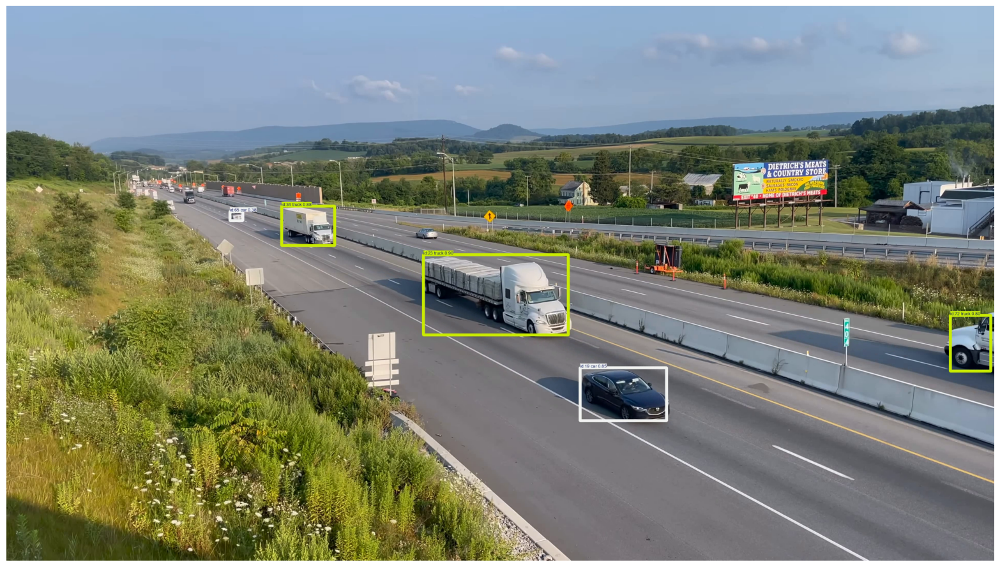

In [18]:
fpath = f"{OUTPUTS_DIR}/track_study_eval_roadside_medium_01.mp4"
frame = get_frame(fpath, 200)
print(f"Frame shape {frame.shape}")
show_frame(frame)

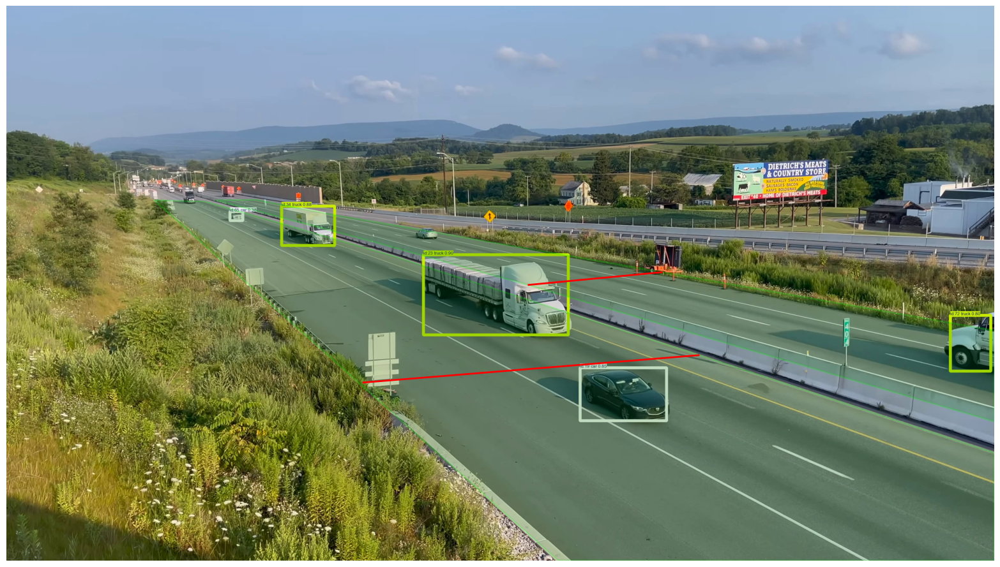

In [19]:
sclip3_inc_line = [[1385, 1467], [2695, 1360]]
sclip3_out_line = [[2027, 1087], [2551, 1037]]
sclip3_lines = [sclip3_inc_line, sclip3_out_line]

sclip3_inc_zone = [[2145, 2160], [574, 757], 
                   [774, 762], [1490, 970], [2695, 1360], [3840, 1740], [3840, 2160]]
sclip3_out_zone = [[3840, 1618], [2027, 1087], [1406, 913], [813, 757],
                   [972, 755], [1287, 817], [1567, 864], [2551, 1037], [3840, 1264]]
sclip3_zones = [sclip3_inc_zone, sclip3_out_zone]

draw_lines_and_zone(frame, sclip3_lines, sclip3_zones)

### **4.3 First Counting Run**

In [20]:
dir_labels = {"negative": "A --> B", "positive": "B --> A"}
model = YOLO("yolov8m.pt")
cap3 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_roadside_medium_01.mp4")
cap3fps = round(cap3.get(cv2.CAP_PROP_FPS))

# Create the counters
sclip3source = "study_eval_roadside_medium_01.mp4"
sclip3_ctr1 = LineCrossingCounter(sclip3source, cap3fps, "incoming", 
                                  sclip3_inc_line, sclip3_inc_zone, 
                                  dir_labels, hys_n=1) 
sclip3_ctr2 = LineCrossingCounter(sclip3source, cap3fps, "outgoing", 
                                  sclip3_out_line, sclip3_out_zone, 
                                  dir_labels, hys_n=1)
sclip3_ctrs1 = (sclip3_ctr1, sclip3_ctr2)

with open(f"{OUTPUTS_DIR}/study_eval_roadside_medium_01.pkl", "rb") as f:
    sclip3_saved = pickle.load(f)

sclip3_log1, sclip3_dets = process_clip(cap=cap3, 
                           out_fname=f"{OUTPUTS_DIR}/study_eval_roadside_medium_01_hysn1.mp4", 
                           model=None,
                           counters=sclip3_ctrs1, 
                           save_path=None, 
                           saved_dets=sclip3_saved, 
                           track_file=TRACK_BF60,
                           log_frames=True) 

Mode: replay of saved detections
(W,H): (3840,2160)
Video FPS: 29.97002997002997
Total frames: 2248
200/2248 processed
400/2248 processed
600/2248 processed
800/2248 processed
1000/2248 processed
1200/2248 processed
1400/2248 processed
1600/2248 processed
1800/2248 processed
2000/2248 processed
2200/2248 processed
Total unique IDs: 53
Duration: 155.8s
Processing FPS: 14.4


In [18]:
line_ids = ["incoming", "outgoing"]
true_totals = [18, 7]
sys_totals = [18, 6]
phantoms = [0, 0]
misses = [0, 1]

get_scores(line_ids, true_totals, sys_totals, phantoms, misses)

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,18,18,0,0,0.000,0.000
outgoing,7,6,0,1,0.143,0.143
total,25,24,0,1,0.040,0.040


**Note:** Incoming counts all 18 vehicles with no errors. But outgoing misses 1 of 7 (14.3% NCE and GER), which is the vehicle whose detection dropped out before it crossed the line and was not able to recover afterwards. That's well over the set targets, but it is a single vehicle out of 7. With so few vehicles, we cannot really tell whether that spot is a real problem. Moving the line to catch that one vehicle would mean fitting it to one car rather than the road. We keep the line where most vehicles show a steady box, keep `hys_n=1`, and let the eval clip show us how this placement holds up with more traffic since it is longer (with duration 0:3:35). These are setup numbers for the study clip, not the reported result.

**Final Config: `study_eval_roadside_medium_01`**

| Line | Counting line (left to right) | Counting zone | `hys_n` |
|---|---|---|---|
| Incoming | `[[1385, 1467], [2695, 1360]]` | `[[2145, 2160], [574, 757], [774, 762], [1490, 970], [2695, 1360], [3840, 1740], [3840, 2160]]` | 1 |
| Outgoing | `[[2027, 1087], [2551, 1037]]` | `[[3840, 1618], [2027, 1087], [1406, 913], [813, 757], [972, 755], [1287, 817], [1567, 864], [2551, 1037], [3840, 1264]]` | 1 |

`cooldown=30` on both lines and `track_buffer=60`. These settings carry over to `eval_roadside_medium_01`.

## **5. Scaling `cooldown` and `track_buffer` Based on Each Clip's Frame Rate**

Until now, `cooldown` and `track_buffer` were set as a number of frames (cooldown is 30 frames while `track_buffer` is 60). The study clip for `eval_roadside_medium_02` (which we will get to below) runs at 60 fps, which means the same frame counts cover much less time:

| Setting | At 25 fps | At 60 fps |
|---|---|---|
| `cooldown=30` | 1.2 s | 0.5 s |
| `track_buffer=60` | 2.4 s | 1.0 s |

The upside of a higher frame rate is that vehicles move half as far or less between frames compared to 25-30 fps, so their boxes overlap more from frame to frame and the tracker matches them more easily. The downside is that a vehicle hidden behind a truck for 1 second now uses up 60 frames of `track_buffer` instead of just 25-30, so with `track_buffer=60` anything hidden for longer than about 1 second loses its track.

To give every clip the same timing, both settings stay as frame counts, but we now determine the exact number of frames based on each clip's frame rate so they always cover the same time (1.2 seconds for cooldown and 2.4 seconds for `track_buffer`) as they do at 25 fps:

- `cooldown = round(1.2 × fps)`
- `track_buffer = round(2.4 × fps)`

| Frame rate | `cooldown` | `track_buffer` |
|---|---|---|
| 25 fps | 30 | 60 |
| 30 fps | 36 | 72 |
| 60 fps | 72 | 144 |

**Note:** All dev clips are at 25 fps, so they keep exactly the settings they were tuned with, and their results still stand.

**How It Works:** 

- At 25 fps, our original `cooldown` of 30 frames lasts 1.2 seconds and our original `track_buffer` of 60 frames lasts 2.4 seconds.
- These are the two times we keep fixed, stored as `COOLDOWN_S = 1.2` and `TRACK_BUFFER_S = 2.4`.
- A helper, `to_frames()`, turns a time into a frame count for a given frame rate, and that gives the exact `cooldown` number of frames
- `cooldown` is then passed straight to each `LineCrossingCounter`.
- `track_buffer` is different, because Ultralytics only reads tracker settings from a YAML file.
- For `track_buffer` we keep one tracker config file per frame rate (25, 30 and 60 fps), each with its `track_buffer` already set.
- This is simply a matter of picking the tracker config file that matches the clip's fps.

`hys_n` stays as counts of sightings rather than being converted based on clip frame rate. Every eval clip uses `hys_n=1` regardless of frame rate. The above rules are set before any eval clip is run, and they will apply in a similar same way to all of them.

In [15]:
COOLDOWN_S = 1.2       # the time 30 frames are covered at 25 fps

def to_frames(seconds, fps):
    return round(seconds * fps)

# One tracker config per frame rate, with track_buffer = raound(2.4 x fps)
TRACKER_FILES = {25: f"{CONFIG_DIR}/bytetrack_25fps.yaml",   # track_buffer: 60
                 30: f"{CONFIG_DIR}/bytetrack_30fps.yaml",   # track_buffer: 72
                 60: f"{CONFIG_DIR}/bytetrack_60fps.yaml"}   # track_buffer: 144

## **6. `eval_roadside_medium_02.mp4` - Determine Eval Settings Using a Study Clip**

- **Study clip used:** `study_eval_roadside_medium_02.mp4`
- **Study clip duration:** 4 minutes
  
### **6.1 Generate and Observe Detections on the Study Clip**

In [23]:
cap4 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_roadside_medium_02.mp4")
model = YOLO("yolov8m.pt")
out_fname = f"{OUTPUTS_DIR}/track_study_eval_roadside_medium_02.mp4"
all_dets4 = generate_detections(cap4, model, out_fname, TRACKER_FILES[60])

# Save the detections for later replays
with open(f"{OUTPUTS_DIR}/study_eval_roadside_medium_02.pkl", "wb") as f:
    pickle.dump(all_dets4, f)
print(f"Saved detections for {len(all_dets4)} frames")  

(W,H): (1920,1080)
video fps: 59.94005994005994
Total frames: 14386
200/14386 processed
400/14386 processed
600/14386 processed
800/14386 processed
1000/14386 processed
1200/14386 processed
1400/14386 processed
1600/14386 processed
1800/14386 processed
2000/14386 processed
2200/14386 processed
2400/14386 processed
2600/14386 processed
2800/14386 processed
3000/14386 processed
3200/14386 processed
3400/14386 processed
3600/14386 processed
3800/14386 processed
4000/14386 processed
4200/14386 processed
4400/14386 processed
4600/14386 processed
4800/14386 processed
5000/14386 processed
5200/14386 processed
5400/14386 processed
5600/14386 processed
5800/14386 processed
6000/14386 processed
6200/14386 processed
6400/14386 processed
6600/14386 processed
6800/14386 processed
7000/14386 processed
7200/14386 processed
7400/14386 processed
7600/14386 processed
7800/14386 processed
8000/14386 processed
8200/14386 processed
8400/14386 processed
8600/14386 processed
8800/14386 processed
9000/14386 p

### **6.2 Determine the Counting Line and Zone**

Frame shape (1080, 1920, 3)


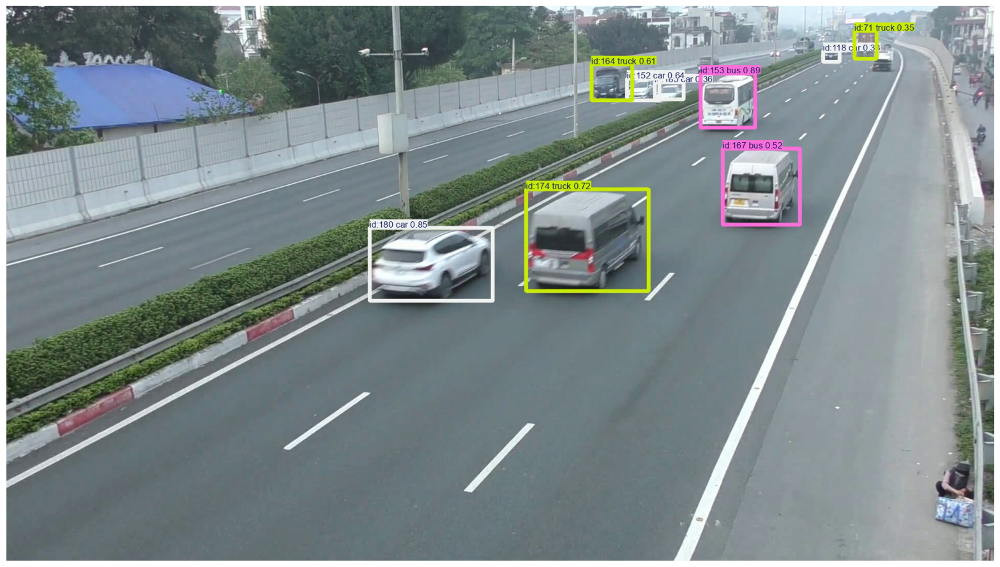

In [49]:
fpath = f"{OUTPUTS_DIR}/track_study_eval_roadside_medium_02.mp4"
frame1 = get_frame(fpath, 1070)
print(f"Frame shape {frame1.shape}")
show_frame(frame1)

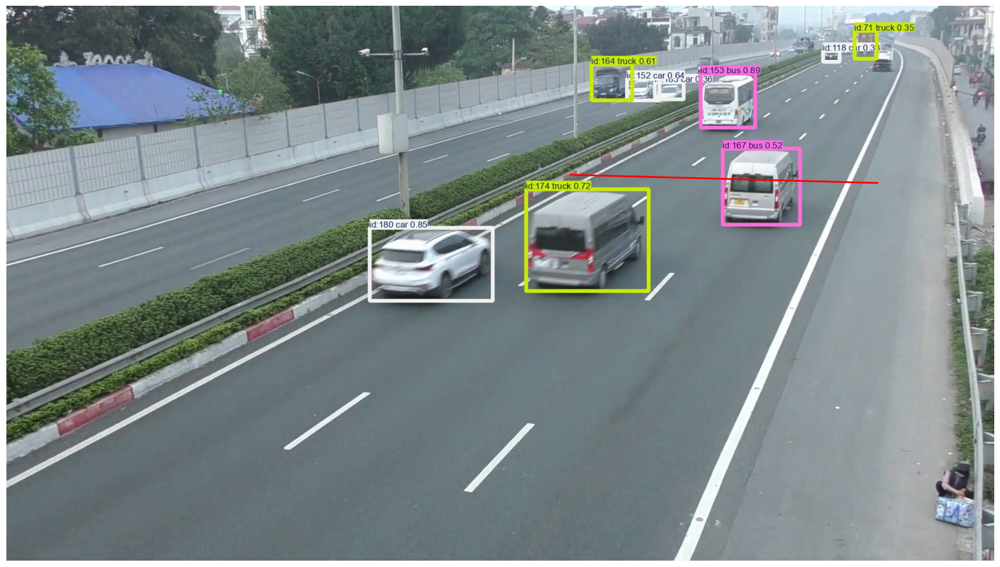

In [50]:
sclip4_out_line = [[1095, 329], [1695, 345]]
sclip4_lines = [sclip4_out_line]
draw_lines_and_zone(frame1, sclip4_lines)

Frame shape (1080, 1920, 3)


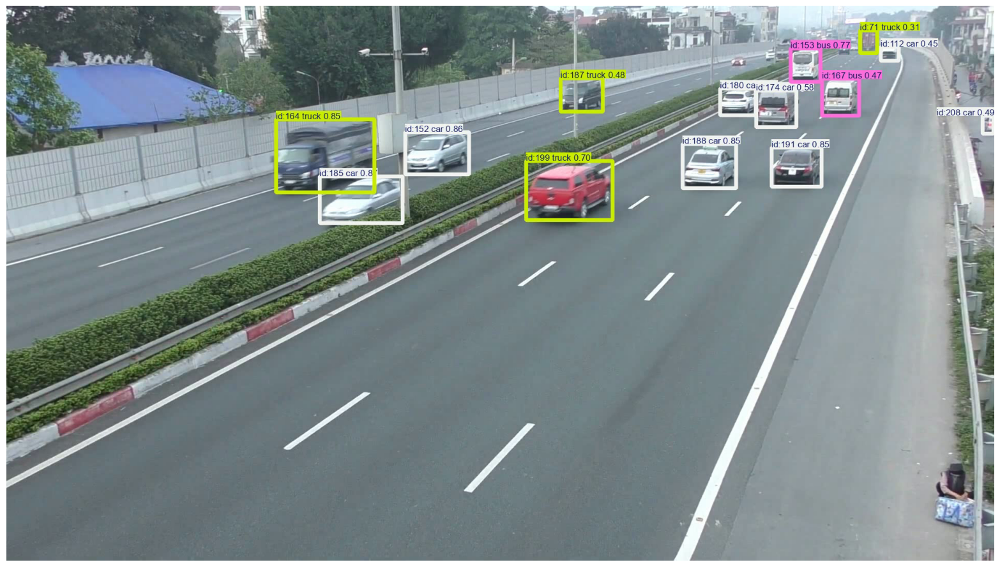

In [51]:
frame2 = get_frame(fpath, 1200)
print(f"Frame shape {frame2.shape}")
show_frame(frame2)

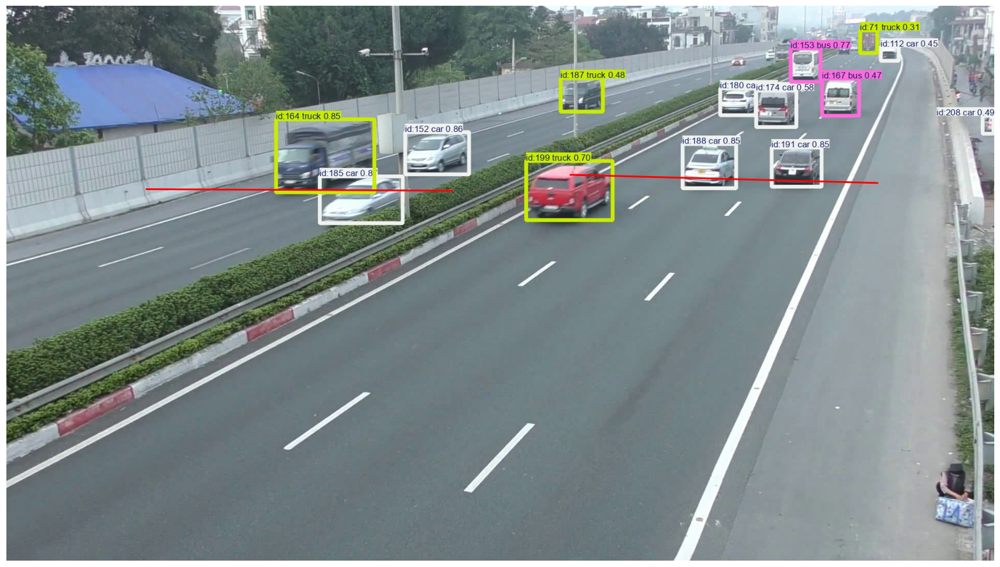

In [52]:
sclip4_inc_line = [[271, 357], [868, 360]]
sclip4_out_line = [[1095, 329], [1695, 345]]
sclip4_lines = [sclip4_inc_line, sclip4_out_line]
draw_lines_and_zone(frame2, sclip4_lines)

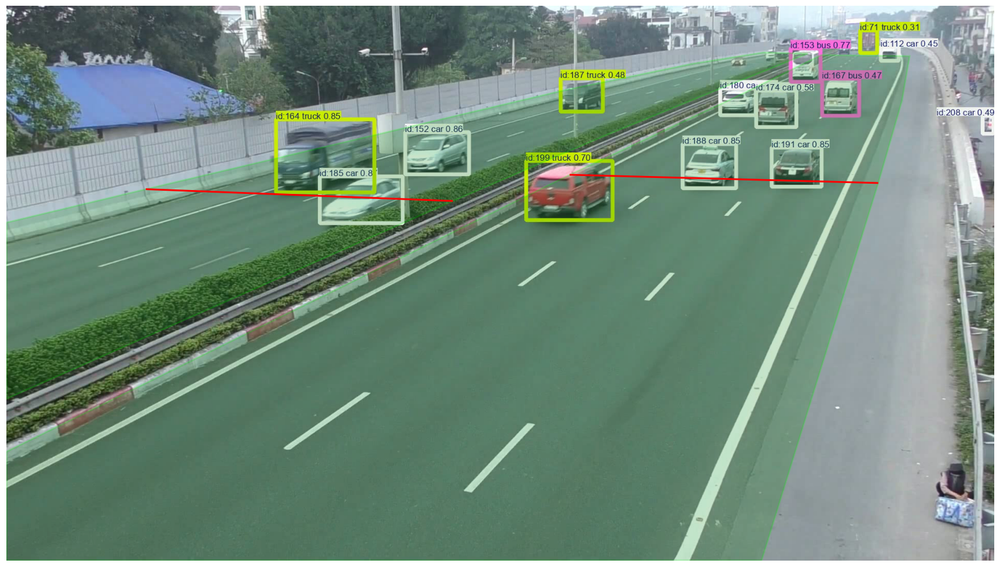

In [65]:
sclip4_inc_line = [[271, 357], [868, 380]]
sclip4_out_line = [[1095, 329], [1695, 345]]
sclip4_lines = [sclip4_inc_line, sclip4_out_line]

sclip4_inc_zone = [[0, 422], [271, 357], [1082, 165], [1333, 113], [1471, 91],
                   [1558, 93], [1376, 166], [1163, 253], [868, 380], [0, 765]]
sclip4_out_zone = [[0, 1080], [0, 868], [1095, 329], [1417, 178], [1584, 96],
                   [1756, 98], [1741, 185], [1695, 345], [1468, 1080]]
sclip4_zones = [sclip4_inc_zone, sclip4_out_zone]

draw_lines_and_zone(frame2, sclip4_lines, sclip4_zones)

### **6.3 First Counting Run**

In [66]:
dir_labels = {"negative": "A --> B", "positive": "B --> A"}
model = YOLO("yolov8m.pt")
cap4 = cv2.VideoCapture(f"{STUDY_CLIPS_DIR}/study_eval_roadside_medium_02.mp4")
cap4fps = round(cap4.get(cv2.CAP_PROP_FPS))
track_file = TRACKER_FILES[60]

# Create the counters
sclip4source = "study_eval_roadside_medium_02.mp4"

sclip4_ctr1 = LineCrossingCounter(sclip4source, cap4fps, "incoming", 
                                  sclip4_inc_line, sclip4_inc_zone, dir_labels, 
                                  cooldown=to_frames(COOLDOWN_S, cap4fps), hys_n=1) 
                                  
sclip4_ctr2 = LineCrossingCounter(sclip4source, cap4fps, "outgoing", 
                                  sclip4_out_line, sclip4_out_zone, dir_labels, 
                                  cooldown=to_frames(COOLDOWN_S, cap4fps), hys_n=1)

sclip4_ctrs1 = (sclip4_ctr1, sclip4_ctr2)

with open(f"{OUTPUTS_DIR}/study_eval_roadside_medium_02.pkl", "rb") as f:
    sclip4_saved = pickle.load(f)

sclip4_log1, sclip4_dets = process_clip(cap=cap4, 
                           out_fname=f"{OUTPUTS_DIR}/study_eval_roadside_medium_02_hysn1.mp4", 
                           model=None,
                           counters=sclip4_ctrs1, 
                           save_path=None, 
                           saved_dets=sclip4_saved, 
                           track_file=track_file,
                           log_frames=True) 

Mode: replay of saved detections
(W,H): (1920,1080)
Video FPS: 59.94005994005994
Total frames: 14386
200/14386 processed
400/14386 processed
600/14386 processed
800/14386 processed
1000/14386 processed
1200/14386 processed
1400/14386 processed
1600/14386 processed
1800/14386 processed
2000/14386 processed
2200/14386 processed
2400/14386 processed
2600/14386 processed
2800/14386 processed
3000/14386 processed
3200/14386 processed
3400/14386 processed
3600/14386 processed
3800/14386 processed
4000/14386 processed
4200/14386 processed
4400/14386 processed
4600/14386 processed
4800/14386 processed
5000/14386 processed
5200/14386 processed
5400/14386 processed
5600/14386 processed
5800/14386 processed
6000/14386 processed
6200/14386 processed
6400/14386 processed
6600/14386 processed
6800/14386 processed
7000/14386 processed
7200/14386 processed
7400/14386 processed
7600/14386 processed
7800/14386 processed
8000/14386 processed
8200/14386 processed
8400/14386 processed
8600/14386 processed


In [67]:
line_ids = ["incoming", "outgoing"]
true_totals = [100, 121]
sys_totals = [100, 120]
phantoms = [3, 1]
misses = [3, 2]

get_scores(line_ids, true_totals, sys_totals, phantoms, misses)

,true_total,sys_total,phantoms,misses,net_count_err,gross_error_rate
incoming,100,100,3,3,0.000,0.060
outgoing,121,120,1,2,0.008,0.025
total,221,220,4,5,0.005,0.041


**Observations:**

See the output video [here](https://youtu.be/4UN5JD_NMnY).

- A few incoming detections are drawn as gray boxes, meaning their anchor points fall outside the incoming counting zone
- These gray boxes all belong to large trucks and they are all close to the camera, where their boxes are tall enough that the bottom edge exceeds the zone.
- We cannot extend the incoming zone to cover these gray boxes, because it already reaches the median barrier between the incoming and outgoing carriageways.
- The good news is that this did not affect the counts. None of the misses came from a vehicle whose anchor was outside the zone as it crossed.
- All misses on both carriageways (3 incoming, 2 outgoing) were vehicles occluded by other vehicles.
- All phantom counts on both carriageways (3 incoming, 1 outgoing) were split detections (one vehicle detected as two boxes).
- There is a pole in front of the traffic just before the incoming line, but it did not cause any of the misses or phantom counts.
- The incoming split detections (all are trucks with trailers) start even before the vehicles reach the pole, so moving the line would not be able to remove them.

**Final Config: `study_eval_roadside_medium_02`**

| Line | Counting line (left to right) | Counting zone | `hys_n` |
|---|---|---|---|
| Incoming | `[[271, 357], [868, 380]]` | `[[0, 422], [271, 357], [1082, 165], [1333, 113], [1471, 91], [1558, 93], [1376, 166], [1163, 253], [868, 380], [0, 765]]` | 1 |
| Outgoing | `[[1095, 329], [1695, 345]]` | `[[0, 1080], [0, 868], [1095, 329], [1417, 178], [1584, 96], [1756, 98], [1741, 185], [1695, 345], [1468, 1080]]` | 1 |

This clip runs at 60 fps, so `cooldown=72` and `track_buffer=144` on both lines (1.2 s and 2.4 s, which are the same times as if the clip is 25 fps). These settings carry over to `eval_roadside_medium_02`.

**Next Step:** That is all four eval clip configurations set up. For the actual evaluation runs, we will use a separate notebook `counting-evaluation`. But first we need to write a `counting_lines_eval.yaml` config file and commit it to the remote repo before the first evaluation run happens locally.